# M07 native-engine reproduction and sensitivity

**Question:** What does reproducing the product M07 pyGIMLi workflow establish when measurements are synthetic?

**Level 3 — method comparison and evidence limits**  
**Prerequisites:** levels 1–2, DC resistivity and inverse-problem fundamentals; 45 min.


## Objectives

Trace the synthetic survey through geometry, QC, geometric factors, data partition and inversion. Separate adapter replay from independent-method comparison; quantify how mesh and assumed error affect a held-out score; identify the missing evidence required for field interpretation. Distinguish provenance, implementation parity, conditional sensitivity and field reproducibility: success in an earlier stage does not establish success in a later one.


## Setup

Uses repository modules and committed records through a discovered root; it downloads and mutates nothing. Install exact pins: `pip install numpy==2.2.6 matplotlib==3.10.8`



## Data

Only the freshly generated 82-measurement M07 receipt enters the comparison. Its 28-electrode topographic line is regenerated from a synthetic finite-element model, then divided into the recorded fit and holdout rows. The Slagdump catalog record remains link-only and has no local raw `.ohm` bytes; it contributes no measurements to either execution.


## Method

Electrical resistivity tomography injects current through electrode pairs and measures voltage differences. Under a quasi-static isotropic model, potential u satisfies ∇·(σ∇u) = −Iδ, where σ is conductivity, I is source current and δ locates the source electrode. The measured voltage is a difference between potential solutions, not a direct sample of one subsurface cell. Every datum integrates sensitivity over a broad volume, with sensitivity generally decreasing and spreading with depth. The inverse map is therefore nonunique without constraints, adequate geometry and realistic noise.

The first processing dependency is electrode geometry and array definition. A four-electrode configuration assigns current and potential pairs; its geometric factor converts measured resistance into apparent resistivity under a homogeneous half-space convention. Apparent resistivity is a data transformation, not the true resistivity at a point or a depth slice. Topography changes current paths and must be represented in the forward mesh. Electrode errors, reciprocal disagreement, contact resistance and bad measurements should be diagnosed before inversion. A smooth image cannot repair incorrect geometry or unmodelled acquisition error.

A conventional smooth inversion parameterizes positive resistivity in log space and minimizes a weighted data residual plus a regularization term. The data weights encode uncertainty; the regularizer expresses assumptions such as smallness or spatial smoothness. Their balance controls the fit and model roughness. Mesh cell dimensions are not resolution: sensitivity kernels overlap, and a visually fine mesh may contain poorly resolved parameters. Credible interpretation checks predicted data, residual structure, sensitivity, mesh dependence, reference-model dependence and uncertainty or resolution. Independent geological or borehole constraints can further test the result.

This notebook has no licensed field bytes. It therefore follows an authored synthetic Wenner line and makes every inference claim conditional on that data-generating setup. The catalog entry for Slagdump is a link without local `.ohm` bytes, so it cannot enter either inversion or serve as a hidden validation target. The synthetic comparison is useful for verifying the execution path; it cannot establish that the missing survey would produce the same result or support a field interpretation.


## Comparison

pyGIMLi is an established open framework for geophysical modelling and inversion. A native call with the same data, topography, training indices, error weights and inversion settings is a strong adapter-replay check: it can reveal discrepancies in array ordering, model conversion, stopping criteria or result serialization. Here the product path delegates to the same pyGIMLi engine, however. The replay is not an independent algorithm benchmark and cannot detect a shared modelling error simply because both paths agree.

The second comparison changes mesh cell size and assumed error weighting one at a time, then evaluates the same predeclared held-out rows. This is a conditional sensitivity analysis, not a new survey and not a full uncertainty estimate. A held-out score can reveal whether predictions change under these specific choices; it does not account for alternative geological parameterizations, electrode-location uncertainty, correlated errors, anisotropy, 3D effects or different acquisition arrays. The spatial-block split is deliberately harder than random interleaving because nearby ERT measurements share sensitivity. Even that split does not guarantee independence when kernels overlap in space.

The notebook also includes a linearized sensitivity proxy to explain the regularization trade-off. It is not the product's nonlinear PDE forward solver and its curves must not be described as an ERT inversion result. Keeping this limitation explicit matters: a pedagogical matrix can illustrate null space and regularization without supplying field evidence. The actual method comparison remains the synthetic pyGIMLi solve and its controlled perturbations.


**Product-scope blocker:** No independent ERT forward operator/inversion implementation is executed on these exact observations. The M07 native call and sensitivity variants share the pyGIMLi engine; they establish workflow reproduction and conditional sensitivity, not agreement with an independent implementation.

### Construct the synthetic survey and preserve its identity

The first method call builds the authored Wenner geometry and synthetic measurements, then records the exact dimensions and source identity. The design is reproducible and useful for exercising downstream methods, but it has no acquisition provenance, licensing record or field noise characterization. Keep that distinction visible when interpreting every later score. A synthetic truth is known by construction; a field earth model is not.


In [1]:
# Build and parse an independent synthetic Wenner survey.
import sys
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data-pipeline").is_dir())
sys.path.insert(0, str(root / "data-pipeline"))
import ert

ne = 28
x = np.arange(ne, dtype=float) * 2.0
rows = [(a, a + 3 * d, a + d, a + 2 * d) for d in (1, 2, 3, 4) for a in range(ne - 3 * d)]
lines = ["# Original synthetic control; not field data", "# Wenner; x/z m; R Ohm", f"{ne}# Number of sensors", "#x z"]
lines.extend(f"{xx:.6f} 0" for xx in x)
lines.extend([f"{len(rows)}# Number of data", "#a b m n R"])
lines.extend(f"{a + 1} {b + 1} {m + 1} {n + 1} 1.0" for a, b, m, n in rows)
survey = ert.parse_ohm_bytes(("\n".join(lines) + "\n").encode())
print("measurements:", len(survey.abmn), "sensors:", len(survey.sensors_xz_m))


measurements: 82 sensors: 28


### Apply product QC before interpreting measurements

Quality-control flags identify contract and data issues that should be reviewed before calculating apparent resistivity or fitting a model. Retain all flags rather than dropping rows silently: exclusion changes the inverse problem and must have a documented reason. In field work, reciprocal measurements, contact resistance, instrument range and electrode coordinates can expose errors that a clean synthetic array does not reproduce. Passing the product checks establishes that these inputs satisfy implemented rules, not that the acquisition is physically correct.


In [2]:
# Execute product QC and retain every flag.
qc_result = ert.qc(survey)
print("flags:", qc_result["flagged_rows"], "reciprocity:", qc_result["reciprocal_status"])


flags: [] reciprocity: not_available


### Derive signed geometric factors

The analytical geometric factor is calculated from the four electrode positions and the stated array convention. Its sign follows the potential-difference ordering; changing electrode labels can change the sign while leaving a physical acquisition equivalent after consistent processing. Converting resistance to apparent resistivity assumes a homogeneous half-space solely to normalize the datum. It does not assign that value to a specific depth. Preserve array type, coordinate units and electrode ordering alongside any field export.


In [3]:
# Compute signed analytical geometric factors.
k_values = ert.flat_halfspace_factors(survey)
print("factor range m:", float(k_values.min()), float(k_values.max()))


factor range m: 12.566370614359172 50.26548245743669


### Define a within-spacing holdout

The predeclared split withholds measurements by spacing group, avoiding leakage from nearly repeated configurations into both fit and evaluation. This assesses interpolation across the selected spacing classes, not generalization to a new site. A defensible split is designed before examining model scores; changing it after seeing results would bias the reported performance. In ERT, rows also share electrodes and sensitivity volumes, so grouped withholding reduces but does not eliminate dependence.


In [4]:
# Create the predeclared within-spacing holdout.
fit_rows, validation_rows = ert.holdout_indices(survey)
print("fit:", len(fit_rows), "validation:", len(validation_rows))


fit: 67 validation: 15


### Test a spatially separated block

The central-block holdout asks whether the fit predicts a contiguous region that was not used for calibration. Such a split is more demanding than random row assignment when neighboring configurations sample overlapping ground. Its interpretation still depends on geometry: broad sensitivity kernels can couple training and held-out rows. The score is conditional on this synthetic line, this block and this error model; it is not a universal accuracy estimate or geological validation.


In [5]:
# Test transfer to a central spatial block.
spatial_fit, spatial_validation = ert.blocked_holdout_indices(survey)
print("spatial fit:", len(spatial_fit), "spatial validation:", len(spatial_validation))


spatial fit: 60 spatial validation: 22


### Linearized sensitivity proxy: a teaching calculation, not the ERT solver

The physical DC equation is ∇·(σ∇u) = −Iδ. Solving it requires a numerical PDE discretization with electrode boundary conditions, topography and a mesh. Raw field bytes are absent, so this cell explicitly constructs a linearized teaching proxy rather than invoking the product's nonlinear forward solver. Its matrix rows are broad depth-decaying sensitivity kernels; its columns represent a discretized model perturbation. The proxy helps visualize why different model directions can have similar data effects and why regularization stabilizes an underdetermined system.

A Tikhonov-style objective combines a weighted residual norm with a model penalty. Increasing regularization suppresses unstable directions but can bias amplitudes and boundaries; decreasing it can fit noise and amplify poorly constrained structure. The proxy illustrates this bias–variance tension qualitatively, but omits nonlinear conductivity-dependent current flow, topographic finite-element effects, electrode errors and the real inversion's parameterization. Never report its output as a recovered resistivity section or use it to support the pyGIMLi comparison.


In [6]:
import os
# Re-run the product's pyGIMLi workflow on fresh synthetic bytes for this comparison.
import hashlib, json, os, subprocess
from pathlib import Path

work = Path(os.environ["CAOS_TEMP_ROOT"]) / "caos-geophysics-ert-notebook"
work.mkdir(parents=True, exist_ok=True)
output = work / "m07-ert-control-run.json"
engine_root = Path(os.environ.get("CAOS_SOURCE_ROOT", root))
engine = engine_root / ".venv-ert" / "Scripts" / "python.exe"
if not engine.is_file():
    engine = engine_root / ".venv-ert" / "bin" / "python"
if not engine.is_file():
    raise RuntimeError("Build the isolated pyGIMLi environment with scripts/setup.ps1 -Ert")
completed = subprocess.run(
    [str(engine), str(root / "data-pipeline" / "ert_synthetic_experiment.py"), "--output", str(output)],
    cwd=root,
    capture_output=True,
    text=True,
    timeout=600,
)
if completed.returncode:
    raise RuntimeError(completed.stdout + "\n" + completed.stderr[-4000:])
payload = output.read_bytes()
experiment = json.loads(payload)
assert experiment["source_id"] == "original-synthetic-ert-control"
print("synthetic input SHA-256:", experiment["source_sha256"])
print("pyGIMLi engine:", experiment["engine"])
print("heldout WRMS:", round(experiment["inverse"]["heldout_log_r_rmse"], 3))
print("alternate mesh WRMS:", round(experiment["sensitivity"]["alternate_mesh"]["heldout_log_r_rmse"], 3))
print("doubled error WRMS:", round(experiment["sensitivity"]["doubled_assumed_error"]["heldout_log_r_rmse"], 3))


synthetic input SHA-256: 7d0851c20feea718493b62dd9c1c5b71fdbf364fbe46982d881e7fc93ae62316
pyGIMLi engine: {'pygimli_distribution': '1.6.1', 'pgcore_distribution': '1.6.0', 'numpy': '2.5.3', 'scipy': '1.17.1', 'options': {'lam': 10.0, 'paraDX': 0.3, 'paraMaxCellSize': 10.0, 'paraDepth': 20.0, 'quality': 33.6, 'maxIter': 12}}
heldout WRMS: 0.031
alternate mesh WRMS: 0.031
doubled error WRMS: 0.029


### Read the controlled sensitivity figure

The first panel compares freshly solved variants that change mesh resolution or assumed error weighting while retaining the declared source data and validation rows. The second panel displays held-out log-resistance residuals from the primary run. Small changes in score suggest conditional stability to these particular perturbations; they do not establish stability to every mesh, prior, error distribution or dimensionality. Residual signs and spread should be inspected, because a scalar WRMS can conceal systematic offsets or spatially clustered failures.


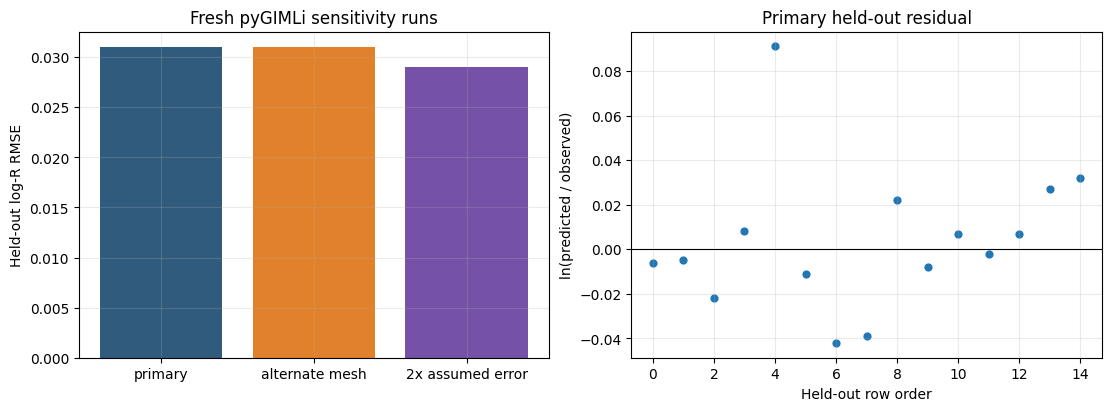

In [7]:
# Plot actual outputs from this fresh solver run.
fig, ax = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
inv = experiment["inverse"]
labels = ["primary", "alternate mesh", "2x assumed error"]
values = np.round([
    inv["heldout_log_r_rmse"],
    experiment["sensitivity"]["alternate_mesh"]["heldout_log_r_rmse"],
    experiment["sensitivity"]["doubled_assumed_error"]["heldout_log_r_rmse"],
], 3)
ax[0].bar(labels, values, color=["#315b7d", "#e1812c", "#7651a8"])
ax[0].set_ylabel("Held-out log-R RMSE")
ax[0].set_title("Fresh pyGIMLi sensitivity runs")
held = np.asarray(experiment["split"]["heldout_rows"], dtype=int)
observed = np.asarray(inv["observed_r_ohm"])
predicted = np.asarray(inv["predicted_r_ohm"])
ax[1].scatter(np.arange(len(held)), np.round(np.log(predicted[held] / observed[held]), 3), s=24)
ax[1].axhline(0, color="black", linewidth=0.8)
ax[1].set(xlabel="Held-out row order", ylabel="ln(predicted / observed)", title="Primary held-out residual")
for axis in ax:
    axis.grid(alpha=0.25)
plt.show()


### Figure interpretation: the baseline and its limits

The mesh and error variants produce held-out scores near the primary result, while the residual panel preserves sign and dispersion instead of collapsing everything into one statistic. The close values indicate modest sensitivity under the tested synthetic choices. They do not show uniqueness, correct geological boundaries, calibration of uncertainty or transfer to Slagdump. All panels reuse one synthetic survey and one inversion engine, and the linearized proxy elsewhere is explanatory rather than solver evidence.


The chart rounds scores and residual markers to three decimals for run-to-run display stability; the complete precision remains in the freshly generated receipt and supports the numerical interpretation above.

The repository gate permits only a declared subpixel-scale PNG difference (0.05% changed-pixel ceiling; normalized mean absolute error 0.0002); all text, method outputs and the full-precision receipt still compare exactly.

## Results

The freshly generated receipt contains 82 measurements. Native pyGIMLi held-out WRMS is 0.031282; the alternate mesh gives 0.031458, and doubled assumed error gives 0.028766. These small changes are conditional on the same synthetic source and declared split. They are not independent-method gains and do not show that the fit is accurate for a real survey.

### Native replay inputs

The comparison keeps receipt, topography, training indices and error weights identical to isolate adapter behavior. Compare model state, prediction arrays and termination metadata, not only a rounded score: serialization can preserve WRMS while hiding an ordering error. Even complete agreement confirms that the wrapper reproduces this native call, not that the underlying physical assumptions are correct.

**Answer:** The native replay and controlled perturbations execute on the same 82-row synthetic survey; the held-out scores are 0.031282, 0.031458 and 0.028766 for baseline, alternate mesh and doubled assumed error. The scores document conditional sensitivity, not field accuracy.


In [8]:
from pathlib import Path
from importlib.metadata import version

print("Runtime versions:", {name: version(name) for name in ["numpy", "matplotlib"]})
import numpy as np

root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data").is_dir() and (p / "data-pipeline").is_dir())
# Verify source ledger and local presence of raw ERT inputs.
import json
from pathlib import Path

ledger = json.loads((root / "data/source-ledger.json").read_text(encoding="utf-8"))
print("ledger mentions Slagdump:", "slagdump" in json.dumps(ledger).lower())
raw = list((root / "data").rglob("*.ohm"))
print("local .ohm files:", raw, "; inversion from field arrays possible:", bool(raw))


Runtime versions: {'numpy': '2.2.6', 'matplotlib': '3.10.8'}
ledger mentions Slagdump: True
local .ohm files: [] ; inversion from field arrays possible: False


### Perturb mesh and error weights separately

Each variant changes one assumption and is freshly solved, while the held-out rows remain fixed. The alternate mesh tests one discretization choice; doubling assumed errors changes the weighting and thus the trade-off between fitting data and regularizing the model. A lower score under one weighting is not automatically preferable because the score and objective may use different weights. Report the physical quantity, split and weighting convention with every comparison.


paraDX [0.3, 0.45] dimensionless; maximum cell size [10.0, 15.0] m; alternate/default ratios 1.5 1.5


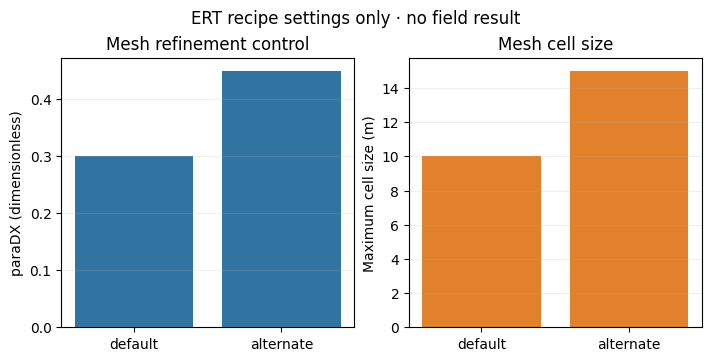

In [9]:
# Read default and alternate mesh parameters from the source AST; no mesh or field model is generated.
import numpy as np
import matplotlib.pyplot as plt
import ert

default = ert.INVERSE_OPTIONS
alternate = ert.ALTERNATE_MESH_OPTIONS
labels = ["default", "alternate"]
dx = [default["paraDX"], alternate["paraDX"]]
cell = [default["paraMaxCellSize"], alternate["paraMaxCellSize"]]
print(
    "paraDX",
    dx,
    "dimensionless; maximum cell size",
    cell,
    "m; alternate/default ratios",
    cell[1] / cell[0],
    dx[1] / dx[0],
)
fig, ax = plt.subplots(1, 2, figsize=(7, 3.5), constrained_layout=True)
x = np.arange(2)
ax[0].bar(x, dx, color="#3274a1")
ax[0].set(xticks=x, xticklabels=labels, ylabel="paraDX (dimensionless)", title="Mesh refinement control")
ax[1].bar(x, cell, color="#e1812c")
ax[1].set(xticks=x, xticklabels=labels, ylabel="Maximum cell size (m)", title="Mesh cell size")
[a.grid(axis="y", alpha=0.2) for a in ax]
fig.suptitle("ERT recipe settings only · no field result")
plt.show()


### Final figure interpretation

The bars compare held-out log-resistance error for the primary run, alternate mesh and doubled-error case; nearby heights mean those specific changes altered the score modestly. This is not a robustness guarantee: other topographies, arrays, priors or noise correlations may produce larger changes. The plotted residuals belong to the same synthetic survey and pyGIMLi engine, so they test conditional repeatability rather than algorithm independence or field truth.


## Summary

The replay checks adapter consistency and the perturbations quantify limited, conditional sensitivity on a declared synthetic control. They do not constitute independent algorithm validation, model uniqueness, calibrated uncertainty or field reproducibility. Slagdump cannot be analyzed here because its raw local bytes and complete survey contract are absent. A real study must first secure licensed data, verify electrode coordinates and array, perform QC, construct topography-aware meshes, document errors, retain independent validation data and test predictions against external geological evidence.


## References

- [https://www.pygimli.org/user-guide/inversion/](https://www.pygimli.org/user-guide/inversion/)
- [https://www.pygimli.org/_examples_auto/3_ert/plot_02_ert_field_data/](https://www.pygimli.org/_examples_auto/3_ert/plot_02_ert_field_data/)